# Offline Evaluation

Every model on the test set, once: the champion chosen in model training, the other ML models, and the baselines. Nothing is chosen or tuned here, so the test scores are an honest estimate of how the champion will do on new data. Each metric has a 95% bootstrap interval. The notebook ends with the evidence; the decision (go, iterate, or no go) is yours.

**How to use this notebook.** The cells marked *Decision* hold the models, the slices, and the bootstrap settings. Edit them, then choose Run All. Raw rows are never shown here.

## Setup

Finds the project root, loads the shared spec `ml_spec.yaml`, and checks the kernel. Run this cell first.

In [1]:
import os
import sys
from pathlib import Path

# The project root is the closest folder with ml_spec.yaml. Everything runs from there.
here = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in here if (p / "ml_spec.yaml").is_file()), Path.cwd())
os.chdir(ROOT)
# The project's own code (src) comes from this folder, also in an experiment's worktree, where the editable
# install in .venv would point to the main project.
sys.path.insert(0, str(ROOT))

# Shared code from the ML project skills
sys.path.insert(0, r"/Users/ani/.claude/skills/ml-offline-evaluation/scripts")
import ml_common
import nb_common
try:  # MLflow tracking, in the ML project skills: keeps a copy of each chart for the stage's run
    import tracking
    tracking.capture_figures()
except ImportError:
    tracking = None

SPEC_PATH = str(ROOT / "ml_spec.yaml")
spec = ml_common.migrate(ml_common.load(SPEC_PATH)) if os.path.exists(SPEC_PATH) else ml_common.template()
PATHS = ml_common.project_paths(spec, str(ROOT))
NOTEBOOK = os.path.join(PATHS["notebooks"], "09_evaluation.ipynb")
STAGE = "evaluation"

print("Project root:", ROOT)
print("Python:", sys.executable)
if (ROOT / ".venv").is_dir() and Path(sys.prefix).resolve() != (ROOT / ".venv").resolve():
    print("Warning: this kernel is not the project's .venv. Choose 'Select Kernel' and pick the project kernel.")

Project root: /Users/ani/Projects/16_weather_prediction
Python: /Users/ani/Projects/16_weather_prediction/.venv/bin/python


In [2]:
import datetime as dt
import importlib
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import precision_recall_curve, roc_curve

import eval_core
import model_core
import split_core

sys.path.insert(0, str(ROOT))   # the project's own src package
import src.features as F
importlib.reload(F)
CHAMP_COLOR, REF_COLOR, OTHER_COLOR = "#c0504d", "#7f7f7f", "#3b75af"

## What This Builds On

The champion, the reference, and whether the test set was opened before.

In [3]:
framing, split, features, baseline, training = (spec.get(k) or {} for k in ("framing", "split", "features", "baseline", "training"))
TASK_TYPE, TARGET = framing.get("task_type"), split.get("target")
FAMILY = model_core.task_family(TASK_TYPE)
CONFIG = F.load_config(spec)
INPUTS = F.feature_columns(CONFIG)
METRICS = baseline["metrics"]
PRIMARY_M = model_core.all_metrics(METRICS)[0]
PRIMARY = baseline["primary_label"]
HIGHER = model_core.HIGHER_IS_BETTER.get(PRIMARY_M["key"]) is not False
CHAMPION = training["champion"]["name"]
REFERENCE = (baseline.get("reference") or {}).get("name")
BEST_BASELINE = (baseline.get("best_non_ml") or {}).get("name")
print(f"Champion: {CHAMPION} ({training['champion']['type']}). Reference: {REFERENCE}. Best baseline: {BEST_BASELINE}")
print(f"Primary metric: {PRIMARY} ({'higher' if HIGHER else 'lower'} is better). V1 bar: {(framing.get('success') or {}).get('v1_bar')}")
opened = (spec.get("evaluation") or {}).get("test_opened") or []
warnings = []
for o in opened:
    if o.get("champion") != CHAMPION or o.get("data_version") != training.get("data_version"):
        warnings.append(f"The test set was opened on {o.get('at')} for champion {o.get('champion')}. The champion or the "
                        "data changed since, so if that change followed the earlier test results, this test score is optimistic.")
print("Test set opened before: " + (f"{len(opened)} time(s)" if opened else "no"))
for w in warnings:
    print("Warning: " + w)

Champion: lightgbm (lightgbm). Reference: naive. Best baseline: naive
Primary metric: mae (lower is better). V1 bar: MAE at least 10% lower than the best simple baseline (persistence, seasonal naive, or moving average) on CV, and still lower than it on the test set
Test set opened before: 2 time(s)


## Settings

Month shows whether the error changes through the season and as the frozen model ages over 26 weeks; latitude bands separate the southern hemisphere (autumn and winter in the test) from the northern summer; city finds places where the model loses to persistence.

*`MODELS_TO_SCORE` is `"all"` or a list of names (the champion is always scored). `SLICES` lists the slice columns: `categorical`, `numeric_bins` (column: number of quantile bins from the training rows), `time` (column and period W or M), `new_entity` (the entity column; slices rows by whether the entity was seen in training), `missing` (columns sliced by missing or present), `protected` (attributes to check for fairness), and the smallest slice to judge (`min_rows`, `min_positives`). `BOOTSTRAP` sets the resamples and the column whose values are resampled whole.*

In [4]:
# Decision
MODELS_TO_SCORE = 'all'

SLICES = {
    'categorical': ['city'],
    'numeric_bins': {'latitude': 4},
    'time': {'column': 'date', 'period': 'M'},
    'new_entity': 'city',
    'missing': [],
    'protected': [],
    'min_rows': 100,
    'min_positives': 30,
}

BOOTSTRAP = {'n': 200, 'cluster': 'date', 'seed': 0}

# Before the test set is opened, every model's CV score is reproduced through the exact definition used here.
# Turn it off only for models too slow to refit; ml-review reports it when it is off.
SELF_CHECK = True

## Score Every Model on the Test Set

In [5]:
train, test = eval_core.load_rows(spec, "train"), eval_core.load_rows(spec, "test")
runs = model_core.RunLog(training["files"]["runs"]).load()
models = eval_core.models_to_score(spec, runs)
if MODELS_TO_SCORE != "all":
    models = [m for m in models if m["name"] in MODELS_TO_SCORE or m["kind"] == "champion"]
for m in models:
    assert not model_core.check_model(m, train, INPUTS, {}), model_core.check_model(m, train, INPUTS, {})
print(f"Test rows: {len(test):,}. Models: {len(models)}")
SELF_CHECK_RESULT = None
if SELF_CHECK:
    SELF_CHECK_RESULT = eval_core.self_check(models, train, split_core.cv_splits(train, split), INPUTS, TARGET, TASK_TYPE,
                                             CONFIG, METRICS, champion_path=training["champion"]["path"])
    display(SELF_CHECK_RESULT.round(6))
    failed = SELF_CHECK_RESULT[SELF_CHECK_RESULT["ok"] == False]  # noqa: E712
    assert failed.empty, ("Stopped before the test set was opened: " + ", ".join(failed["model"]) + " do not reproduce "
                          "their recorded CV score through the evaluation's scoring path, so their test scores would "
                          "be wrong. Fix the scoring code (eval_core.models_to_score or model_core), then run again.")
preds = eval_core.predict_all(models, train, test, INPUTS, TARGET, FAMILY, CONFIG, champion_path=training["champion"]["path"])
for n, p in preds.items():
    missing = int(np.isnan(np.asarray(p, dtype=float)).sum())
    if missing and FAMILY == "binary":
        # A rule or a column baseline gives no score where its input is missing: those rows rank last, as in training
        preds[n] = np.where(np.isnan(p), np.nanmin(p) - 1e-6, p)
        print(f"{n}: {missing:,} test rows had no score and rank last.")
    elif missing:
        print(f"{n}: {missing:,} test rows have no prediction and are left out of its metrics.")
label = lambda name: f"{name} (champion)" if name == CHAMPION else name

Test rows: 9,100. Models: 5


Self-check: every scoring path reproduces its recorded result.


,model,kind,check,recorded,recomputed,rel_diff,ok
0,lightgbm,champion,saved model against a fresh fit,NaN,NaN,0.000000,True
1,ridge,ml,CV mae reproduced,2.230134,2.230134,0.000000,True
2,naive,baseline,CV mae reproduced,2.515600,2.515648,0.000019,True
3,seasonal_naive,baseline,CV mae reproduced,3.327000,3.327011,0.000003,True
4,moving_average,baseline,CV mae reproduced,2.774000,2.774013,0.000005,True


lightgbm (champion): scored


ridge (ml): scored
naive (baseline): scored
seasonal_naive (baseline): scored
moving_average (baseline): scored


## Metrics on the Test Set

Every metric for every model. The primary metric has a 95% bootstrap interval; `CV` is the model's mean CV score, and `CV to test` the change (a large drop means the tuning fitted the folds, or the data changed over time).

In [6]:
cluster = BOOTSTRAP.get("cluster")
rows = []
for m in models:
    p = preds[m["name"]]
    row = {"model": label(m["name"]), "kind": m["kind"]}
    for met in model_core.all_metrics(METRICS):
        row[model_core.metric_label(met)] = eval_core.metric_fn(met, test, TARGET, p, m["type"])(np.arange(len(test)))
    lo, hi = eval_core.bootstrap(eval_core.metric_fn(PRIMARY_M, test, TARGET, p, m["type"]), test, cluster,
                                 BOOTSTRAP.get("n", 200), BOOTSTRAP.get("seed", 0))
    row.update({"low": lo, "high": hi, "CV": m.get("cv")})
    row["CV to test"] = row[PRIMARY] - row["CV"] if row["CV"] is not None else None
    rows.append(row)
metrics = pd.DataFrame(rows)
display(metrics.round(4))

,model,kind,mae,rmse,bias,low,high,CV,CV to test
0,lightgbm (champion),champion,2.0799,2.8643,-0.0576,2.0376,2.1269,2.1630,-0.0831
1,ridge,ml,2.1460,2.9383,-0.1562,2.1005,2.1922,2.2301,-0.0841
2,naive,baseline,2.4434,3.4264,-0.0425,2.3944,2.5112,2.5156,-0.0722
3,seasonal_naive,baseline,3.2353,4.3304,-0.3066,3.1749,3.3064,3.3270,-0.0917
4,moving_average,baseline,2.6066,3.6033,-0.4323,2.5247,2.6745,2.7740,-0.1674


### Champion Against the Reference

The paired difference on the same bootstrap samples: if the interval stays above zero, the improvement is unlikely to be noise. Positive is better, also for error metrics.

In [7]:
by_name = {m["name"]: m for m in models}
def paired(a, b):
    fa = eval_core.metric_fn(PRIMARY_M, test, TARGET, preds[a], by_name[a]["type"])
    fb = eval_core.metric_fn(PRIMARY_M, test, TARGET, preds[b], by_name[b]["type"])
    sign = 1 if HIGHER else -1
    diff = sign * (fa(np.arange(len(test))) - fb(np.arange(len(test))))
    lo, hi = eval_core.bootstrap(lambda i, d=None: sign * (fa(i, d) - fb(i, d)), test, cluster, BOOTSTRAP.get("n", 200), BOOTSTRAP.get("seed", 0))
    return {"comparison": f"{a} against {b}", "difference": diff, "low": lo, "high": hi,
            "relative %": diff / abs(fb(np.arange(len(test)))) * 100 if fb(np.arange(len(test))) else None}
comparisons = [paired(CHAMPION, n) for n in dict.fromkeys([REFERENCE, BEST_BASELINE]) if n in preds]
comparisons = pd.DataFrame(comparisons)
display(comparisons.round(4))

,comparison,difference,low,high,relative %
0,lightgbm against naive,0.3635,0.3228,0.4058,14.8768


## Charts

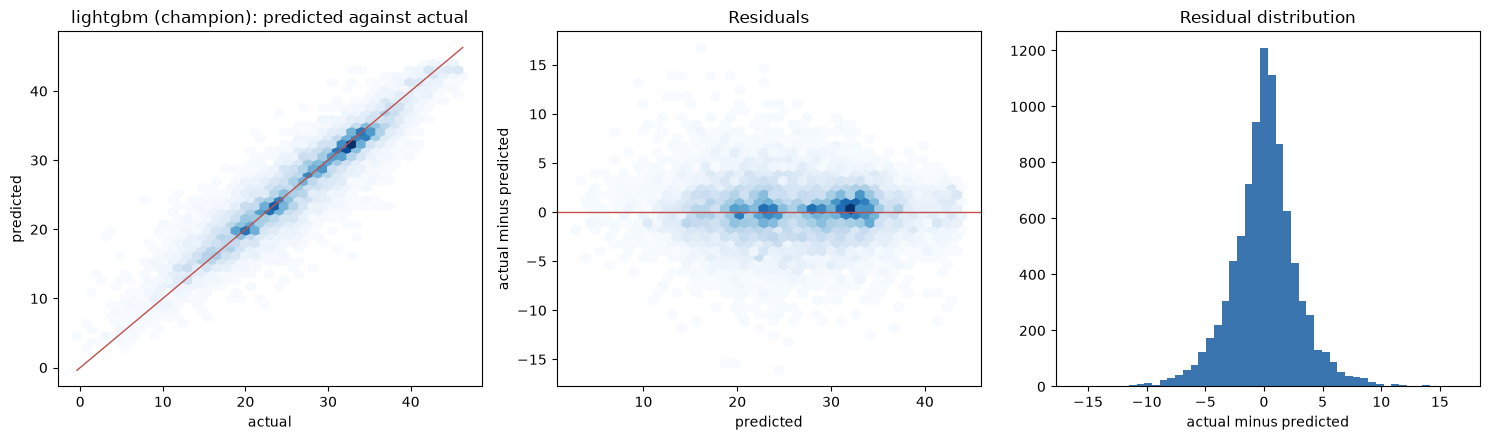

In [8]:
names = [m["name"] for m in models]
style = lambda n: dict(color=CHAMP_COLOR if n == CHAMPION else REF_COLOR if n == REFERENCE else OTHER_COLOR,
                       linewidth=2.5 if n == CHAMPION else 1.2, alpha=1 if n in (CHAMPION, REFERENCE) else 0.6,
                       linestyle="--" if by_name[n]["kind"] == "baseline" else "-")
y = test[TARGET].values
if FAMILY == "binary":
    # Gain curve: share of all positives found against the share of rows acted on
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    for n in names:
        share, found = eval_core.gain_curve(y, preds[n])
        ax[0].plot(share, found, label=label(n), **style(n))
    ax[0].plot([0, 1], [0, 1], color="#d9d9d9", linewidth=1)
    if PRIMARY_M["key"].endswith("_at_k"):
        cap = PRIMARY_M.get("k_share") or (PRIMARY_M["k"] / (test.groupby(PRIMARY_M["k_per"]).size().median() if PRIMARY_M.get("k_per") else len(test)))
        ax[0].axvline(min(cap, 1), color="#999999", linestyle=":", linewidth=1)
        ax[0].text(min(cap, 1), 0.02, " capacity", color="#666666")
    ax[0].set_xlabel("share of rows acted on, best scores first")
    ax[0].set_ylabel("share of all positives found")
    ax[0].set_title("Gain curve")
    ax[0].legend(fontsize=8)
    # The primary "at k" metric for other capacities
    if PRIMARY_M["key"].endswith("_at_k"):
        base_k = PRIMARY_M.get("k") or PRIMARY_M.get("k_share")
        grid = [base_k * f for f in (0.25, 0.5, 0.75, 1, 1.5, 2, 3)]
        for n in names:
            vals = [model_core.score_metric({**PRIMARY_M, ("k" if PRIMARY_M.get("k") else "k_share"): (int(round(g)) if PRIMARY_M.get("k") else min(g, 1))},
                                            y, preds[n], test[PRIMARY_M["k_per"]].values if PRIMARY_M.get("k_per") else None) for g in grid]
            ax[1].plot(grid, vals, marker=".", label=label(n), **style(n))
        ax[1].axvline(base_k, color="#999999", linestyle=":", linewidth=1)
        ax[1].set_xlabel("k" + (f" per {PRIMARY_M['k_per']}" if PRIMARY_M.get("k_per") else ""))
        ax[1].set_ylabel(PRIMARY_M["key"].replace("_at_k", " at k"))
        ax[1].set_title("If the capacity changes")
    # ROC and precision recall curves. A model with one score for every row (the base rate) has no curve.
    curved = [n for n in names if len(np.unique(preds[n])) > 1]
    def roc_plot(a):
        for n in curved:
            f, t, _ = roc_curve(y, preds[n])
            a.plot(f, t, label=label(n), **style(n))
        a.plot([0, 1], [0, 1], color="#d9d9d9", linewidth=1)
        a.set_xlabel("false positive rate"); a.set_ylabel("true positive rate"); a.set_title("ROC curve")
    def pr_plot(a):
        for n in curved:
            p, r, _ = precision_recall_curve(y, preds[n])
            if len(np.unique(preds[n])) <= 10:
                # A rule with a few scores has a few real points; a line between them would be invented
                a.plot(r[:-1], p[:-1], marker="o", linestyle="none", label=label(n), color=style(n)["color"])
            else:
                a.plot(r, p, label=label(n), **style(n))
        a.axhline(y.mean(), color="#d9d9d9", linewidth=1, label="positive share")
        a.set_xlabel("recall"); a.set_ylabel("precision"); a.set_title("Precision recall curve")
    if not PRIMARY_M["key"].endswith("_at_k"):
        roc_plot(ax[1])
    plt.tight_layout()
    plt.show()
    if PRIMARY_M["key"].endswith("_at_k"):
        fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
        roc_plot(ax[0]); pr_plot(ax[1]); ax[0].legend(fontsize=8)
    else:
        fig, ax = plt.subplots(figsize=(6, 4.5))
        pr_plot(ax); ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()
else:
    p = preds[CHAMPION]
    fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
    small = len(y) <= 5000   # points for small test sets, density for large ones
    draw = (lambda a, u, v: a.scatter(u, v, s=8, alpha=0.4, color=OTHER_COLOR)) if small else            (lambda a, u, v: a.hexbin(u, v, gridsize=40, mincnt=1, cmap="Blues"))
    draw(ax[0], y, p)
    lim = [min(y.min(), p.min()), max(y.max(), p.max())]
    ax[0].plot(lim, lim, color=CHAMP_COLOR, linewidth=1)
    ax[0].set_xlabel("actual"); ax[0].set_ylabel("predicted"); ax[0].set_title(f"{label(CHAMPION)}: predicted against actual")
    draw(ax[1], p, y - p)
    ax[1].axhline(0, color=CHAMP_COLOR, linewidth=1)
    ax[1].set_xlabel("predicted"); ax[1].set_ylabel("actual minus predicted"); ax[1].set_title("Residuals")
    ax[2].hist(y - p, bins=50, color=OTHER_COLOR)
    ax[2].set_xlabel("actual minus predicted"); ax[2].set_title("Residual distribution")
    plt.tight_layout()
    plt.show()

### Over Time and at the Operating Point

The primary metric for each period of the test set, for the champion and the reference. For classification, also the champion's calibration, its scores by class, and what happens at the operating point (the rows it would act on).

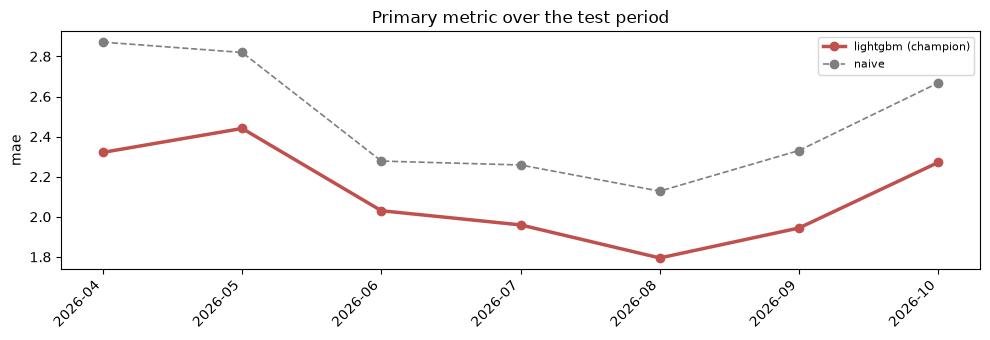

In [9]:
date_col = split.get("date_col")
oof_all = pd.read_parquet(training["files"]["oof_predictions"])
champ_oof = oof_all[oof_all["model"] == CHAMPION].merge(train[[split.get("row_id_col") or "row_id", TARGET]], on=split.get("row_id_col") or "row_id")
act = {}
for n in dict.fromkeys([CHAMPION, REFERENCE]):
    if FAMILY == "binary" and n in preds:
        mask, how = eval_core.operating_mask(spec, test, preds[n], champ_oof["prediction"].values if n == CHAMPION else None,
                                             champ_oof[TARGET].values if n == CHAMPION else None)
        act[n] = mask
        if n == CHAMPION:
            OPERATING = how
if date_col and date_col in test:
    d = pd.to_datetime(test[date_col], errors="coerce", format="mixed")
    period = d.dt.to_period("W" if (d.max() - d.min()).days <= 120 else "M").astype(str)
    if PRIMARY_M.get("k_per") == date_col:
        period = test[date_col].astype(str)
    per = []
    for value, idx in pd.Series(np.arange(len(test))).groupby(period.values):
        idx = idx.values
        for n in dict.fromkeys([CHAMPION, REFERENCE]):
            if n in preds:
                per.append({"period": value, "model": label(n),
                            PRIMARY: eval_core.metric_fn(PRIMARY_M, test, TARGET, preds[n], by_name[n]["type"])(idx)})
    per = pd.DataFrame(per)
    fig, ax = plt.subplots(figsize=(10, 3.5))
    for n in dict.fromkeys([CHAMPION, REFERENCE]):
        g = per[per.model == label(n)]
        ax.plot(g["period"], g[PRIMARY], marker="o", label=label(n), **style(n))
    ax.set_ylabel(PRIMARY); ax.set_title("Primary metric over the test period"); ax.legend(fontsize=8)
    plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()
if FAMILY == "binary":
    p = preds[CHAMPION]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    grp = pd.qcut(pd.Series(p).rank(method="first"), 10, labels=False)
    cal = pd.DataFrame({"p": p, "y": y}).groupby(grp.values).mean()
    CALIBRATION = {"mean_predicted": float(p.mean()), "observed_rate": float(y.mean()),
                   "largest_decile_gap": float((cal.p - cal.y).abs().max())}
    print(f"Mean predicted {CALIBRATION['mean_predicted']:.4f}, observed rate {CALIBRATION['observed_rate']:.4f}, "
          f"largest gap in a tenth of the scores {CALIBRATION['largest_decile_gap']:.4f}.")
    lim = max(cal.p.max(), cal.y.max()) * 1.05
    ax[0].plot([0, lim], [0, lim], color="#d9d9d9"); ax[0].plot(cal.p, cal.y, marker="o", color=CHAMP_COLOR)
    ax[0].set_xlabel("predicted"); ax[0].set_ylabel("observed"); ax[0].set_title(f"Calibration of {label(CHAMPION)}")
    bins = np.linspace(p.min(), p.max(), 40)
    ax[1].hist(p[y == 0], bins=bins, alpha=0.6, color=REF_COLOR, label="negative", density=True)
    ax[1].hist(p[y == 1], bins=bins, alpha=0.6, color=CHAMP_COLOR, label="positive", density=True)
    ax[1].set_title("Scores by class"); ax[1].legend()
    plt.tight_layout(); plt.show()
    sel = act[CHAMPION]
    confusion = pd.DataFrame({"acted on": [int((sel & (y == 1)).sum()), int((sel & (y == 0)).sum())],
                              "not acted on": [int((~sel & (y == 1)).sum()), int((~sel & (y == 0)).sum())]},
                             index=["positive", "negative"])
    print(f"Operating point: {OPERATING}")
    display(confusion)
    if REFERENCE in act:
        found_c, found_r = int((act[CHAMPION] & (y == 1)).sum()), int((act[REFERENCE] & (y == 1)).sum())
        print(f"At this operating point the champion finds {found_c:,} positives, the reference {found_r:,} "
              f"({found_c - found_r:+,}), out of {int(y.sum()):,} in the test set.")
else:
    OPERATING = None
    CALIBRATION = None

## Slices

The primary metric in each slice, for the champion and the reference, with a 95% interval for the difference. Slices below the minimum size are shown but not judged.

For an "at k" metric the top k is chosen on the whole test set, as in production, and each slice shows the result among its own rows, with the share of the slice each model acts on. Slicing by a feature the model ranks on usually shows trade offs: the champion moves capacity towards some slices and away from others, so a slice where it finds fewer positives than the reference is where the capacity went elsewhere, not necessarily an error. A slice is flagged when the whole interval says the champion is worse there.

Overall mae of the champion: 2.0799


,slice,value,rows,target mean,champion,reference,champion better by,interval,too small,worse than reference,far below overall
0,city,Addis Ababa,182,22.6912,0.9654,1.0753,0.1099,0.040 to 0.188,False,False,False
1,city,Anchorage,182,14.8797,2.2988,2.4209,0.1221,-0.087 to 0.297,False,False,False
2,city,Athens,182,29.0253,2.0777,2.4599,0.3822,0.215 to 0.595,False,False,False
3,city,Auckland,182,16.2176,1.0807,1.2725,0.1918,0.081 to 0.315,False,False,False
4,city,Bangkok,182,33.6505,1.2185,1.4214,0.2029,0.093 to 0.305,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...
57,date by month,2026-07,1550,28.2003,1.9596,2.2585,0.2988,0.242 to 0.375,False,False,False
58,date by month,2026-08,1550,28.1972,1.7948,2.1279,0.3332,0.271 to 0.404,False,False,False
59,date by month,2026-09,1500,26.3893,1.9442,2.3307,0.3865,0.317 to 0.459,False,False,False
60,date by month,2026-10,50,25.2480,2.2713,2.6680,0.3967,NaN,True,False,False


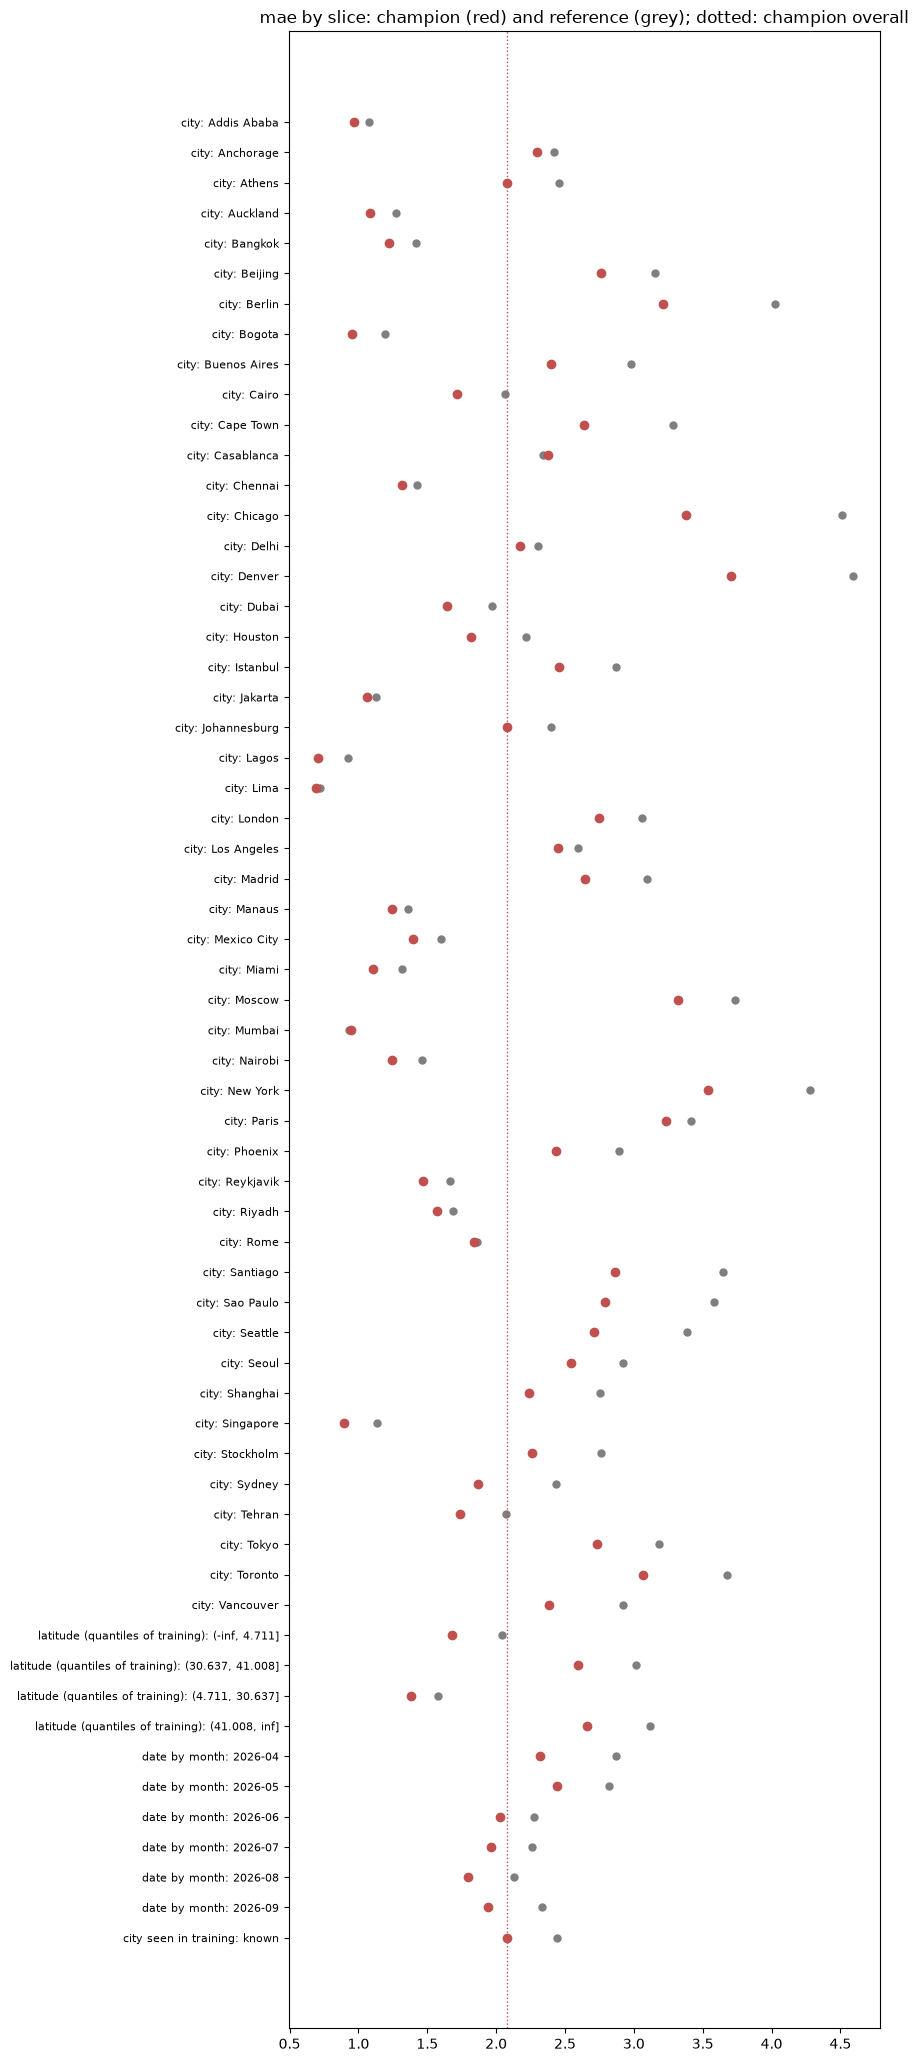

Slices to look at: city = Beijing, city = Berlin, city = Cape Town, city = Chicago, city = Denver, city = London, city = Madrid, city = Moscow, city = New York, city = Paris, city = Santiago, city = Sao Paulo, city = Seattle, city = Tokyo, city = Toronto, latitude (quantiles of training) = (41.008, inf]


In [10]:
if FAMILY != "binary":
    act = {n: None for n in preds}
ref_for_slices = REFERENCE if REFERENCE in preds else next(n for n in names if n != CHAMPION)
slices_df, overall = eval_core.slice_table(spec, test, train, TARGET, preds, CHAMPION, ref_for_slices, SLICES, act,
                                           n_boot=100, seed=BOOTSTRAP.get("seed", 0))
print(f"Overall {PRIMARY} of the champion: {overall:.4f}")
display(slices_df)
judged = slices_df[~slices_df["too small"]].reset_index(drop=True)
if len(judged):
    fig, ax = plt.subplots(figsize=(9, 0.32 * len(judged) + 1.2))
    for i, r in enumerate(judged.itertuples()):
        ax.plot([r.reference], [i], "o", color=REF_COLOR, markersize=5)
        ax.plot([r.champion], [i], "o", color=CHAMP_COLOR, markersize=6)
    ax.axvline(overall, color=CHAMP_COLOR, linestyle=":", linewidth=1)
    ax.set_yticks(range(len(judged)), [f"{r.slice}: {r.value}" for r in judged.itertuples()], fontsize=8)
    ax.invert_yaxis()
    ax.set_title(f"{PRIMARY} by slice: champion (red) and reference (grey); dotted: champion overall")
    plt.tight_layout(); plt.show()
weak = slices_df[slices_df["worse than reference"] | slices_df["far below overall"]]
print("Slices to look at: " + ("none" if weak.empty else ", ".join(f"{r.slice} = {r.value}" for r in weak.itertuples())))

## Feature Importance on the Test Set

Permutation importance of the champion on the test rows, next to its importance in model training. A feature that matters much more or much less on test than in training deserves a look.

In [11]:
import joblib
from sklearn.inspection import permutation_importance
pipe = joblib.load(training["champion"]["path"])
rows_imp = np.arange(len(test)) if len(test) <= 20_000 else np.random.default_rng(0).choice(len(test), 20_000, replace=False)
scoring = "roc_auc" if FAMILY == "binary" else "neg_mean_absolute_error"
imp = permutation_importance(pipe, test.iloc[rows_imp][INPUTS], test.iloc[rows_imp][TARGET], scoring=scoring, n_repeats=3, random_state=0)
cv_imp = {f["feature"]: f["importance"] for f in training.get("top_features") or []}
importance = pd.DataFrame({"feature": INPUTS, "test": imp.importances_mean, "training": [cv_imp.get(c) for c in INPUTS]})
importance = importance.sort_values("test", ascending=False).reset_index(drop=True)
display(importance.head(15).round(4))

,feature,test,training
0,temperature_2m_max_roll_7d_mean_shift_2d,1.6096,1.9041
1,temperature_2m_max_lag_2d,0.9884,2.0009
2,temperature_2m_max_roll_28d_mean_shift_2d,0.6909,0.9302
3,temperature_2m_mean_lag_2d,0.1793,0.0830
4,shortwave_radiation_sum_lag_2d,0.1193,0.1857
5,latitude,0.0875,0.0738
6,temperature_2m_max_lag_364d,0.0807,0.0838
7,temperature_2m_max_lag_7d,0.0298,0.0630
8,date_dayofyear,0.0217,NaN
9,longitude,0.0158,NaN


## Score Drift

The champion's scores on the training rows (out of fold) against the test rows (PSI). Under 0.1 is stable; over 0.25 means the data the model sees has shifted.

In [12]:
score_psi = eval_core.psi(champ_oof["prediction"].values, preds[CHAMPION]) if len(champ_oof) else None
target_psi = None
if score_psi is not None and FAMILY != "binary":
    # For regression and forecasting, a shift in the predictions is expected when the actual values moved too
    target_psi = eval_core.psi(champ_oof[TARGET].values, y)
    print(f"Mean prediction: {np.nanmean(champ_oof['prediction']):.4g} out of fold, {np.nanmean(preds[CHAMPION]):.4g} on test. "
          f"Mean actual: {np.nanmean(champ_oof[TARGET]):.4g} out of fold, {np.nanmean(y):.4g} on test.")
print(f"Score drift (PSI): {score_psi:.3f}" if score_psi is not None else "No out of fold predictions to compare with.")
if target_psi is not None:
    print(f"Drift of the actual values (PSI): {target_psi:.3f}")

Mean prediction: 22.53 out of fold, 26.22 on test. Mean actual: 22.48 out of fold, 26.28 on test.
Score drift (PSI): 0.311
Drift of the actual values (PSI): 0.256


## Evidence

The questions a go, iterate, or no go decision rests on, answered from the results above. The decision is yours: record it, with the reason, in the decisions below or with the next skill you run.

In [13]:
import re
champ = metrics[metrics.kind == "champion"].iloc[0]
evidence = []
def add(q, a):
    evidence.append({"question": q, "answer": a})
for c in comparisons.to_dict("records"):
    sure = "the interval is above zero" if c["low"] > 0 else "the interval includes zero, so it may be noise" if c["high"] > 0 else "the interval is below zero"
    rel = f" ({c['relative %']:+.1f}%)" if c["relative %"] is not None else ""
    add(f"Does the champion beat {c['comparison'].split(' against ')[1]} on the test set?",
        f"{'Yes' if c['difference'] > 0 else 'No'}: by {c['difference']:+.4f}{rel}, 95% interval {c['low']:+.4f} to {c['high']:+.4f}; {sure}.")
# The V1 bar from framing.success.v1_criteria: the test criteria here, the CV criteria from model training
import joblib
v1_text = str((framing.get("success") or {}).get("v1_bar") or "")
test_scores = {r["model"].replace(" (champion)", ""): {k: v for k, v in r.items() if k not in ("model", "kind", "low", "high", "CV", "CV to test")}
               for r in metrics.to_dict("records")}
champ_def = next(m for m in models if m["kind"] == "champion")
v1_ctx = model_core.V1Context(spec, str(ROOT), "test", champ_def, train, INPUTS, TARGET, FAMILY, CONFIG,
                              split_core.cv_splits(train, spec["split"]),
                              pipeline=joblib.load(training["champion"]["path"]), test=test)
v1_test = ml_common.v1_evaluate(spec, "test", test_scores, CHAMPION, REFERENCE, model_core.run_v1_checks(v1_ctx), primary=PRIMARY)
v1_cv = (training.get("champion") or {}).get("v1") or {"on": "cv", "status": "not_set", "criteria": []}
order = ["not_met", "incomplete", "needs_human", "met"]
judged = [r["status"] for r in (v1_cv, v1_test) if r["status"] != "not_set"]
V1 = {"cv": v1_cv, "test": v1_test, "status": next((s for s in order if s in judged), "not_set")}
for r in v1_test["criteria"]:
    print(f"V1 {r['id']} ({r['kind']}, test): {r['status']}. {r['detail']}")
if V1["status"] == "not_set":
    add("Is the V1 bar met?", f"{v1_text or 'No V1 bar set'}. There are no V1 criteria, so compare it with the results above by hand.")
else:
    add("Is the V1 bar met?", f"{V1['status'].replace('_', ' ')}. On CV: {ml_common.v1_summary(v1_cv)}. On test: {ml_common.v1_summary(v1_test)}.")
add("How does the test score compare with CV?",
    f"Test {champ[PRIMARY]:.4f}, CV {champ['CV']:.4f} ({champ['CV to test']:+.4f}). " +
    ("A large drop: the tuning may have fitted the folds, or the data changed." if champ['CV'] and abs(champ['CV to test']) > 0.15 * abs(champ['CV']) else "Close, so the CV estimate held."))
best_other = metrics[metrics.kind != "champion"].sort_values(PRIMARY, ascending=not HIGHER).iloc[0]
add("Is any other model better on the test set?",
    f"{'Yes' if (best_other[PRIMARY] > champ[PRIMARY] if HIGHER else best_other[PRIMARY] < champ[PRIMARY]) else 'No'}: the best other is "
    f"{best_other['model']} with {best_other[PRIMARY]:.4f}. The champion was fixed before the test set was opened; switching now would make its test score optimistic.")
def _names(df):
    return ", ".join(f"{r['slice']} = {r['value']}" for r in df.to_dict("records"))
if weak.empty:
    add("Are there weak slices?", "None found.")
elif "champion acts on" in weak:
    shifted = weak[weak["champion acts on"] < weak["reference acts on"]]
    rest = weak.drop(shifted.index)
    parts = []
    if len(shifted):
        parts.append(f"{len(shifted)} where the reference finds more because the champion acts on fewer of their rows "
                     f"(it sends its capacity to other rows, which the overall comparison judges): {_names(shifted)}.")
    if len(rest):
        parts.append(f"{len(rest)} where the champion acts on as many rows and still finds fewer positives: {_names(rest)}.")
    add("Are there weak slices?", " ".join(parts))
else:
    add("Are there weak slices?", f"{len(weak)}: {_names(weak)}.")
if CALIBRATION:
    ratio = CALIBRATION["mean_predicted"] / max(CALIBRATION["observed_rate"], 1e-9)
    add("Can the scores be read as probabilities?",
        f"Mean predicted {CALIBRATION['mean_predicted']:.4f} against an observed rate of {CALIBRATION['observed_rate']:.4f}; "
        f"the largest gap in a tenth of the scores is {CALIBRATION['largest_decile_gap']:.4f}. " +
        ("Close enough to read as probabilities." if 0.8 <= ratio <= 1.25 else
         "Not as probabilities without calibration; ranking is unaffected.") +
        (" Class weights were used, which raises the scores." if training["champion"].get("class_weight") else ""))
def _level(v):
    return "stable" if v < 0.1 else "a moderate shift" if v < 0.25 else "a large shift"
if score_psi is not None and target_psi is None:
    add("Has the data shifted?", f"Score drift (PSI) {score_psi:.3f}: {_level(score_psi)}.")
elif score_psi is not None:
    add("Has the data shifted?",
        f"Prediction drift (PSI) {score_psi:.3f}, {_level(score_psi)}; drift of the actual values {target_psi:.3f}, "
        f"{_level(target_psi)}. " + ("The actual values moved as well, so the shift comes from the data; the bias "
                                     "metric shows whether the model kept up." if target_psi >= 0.1 and score_psi >= 0.1 else
                                     "The predictions moved more than the actual values: check the inputs that changed most."
                                     if score_psi >= 0.1 else "Both are stable."))
for w in warnings:
    add("Was the test set used before?", w)
evidence = pd.DataFrame(evidence)
with pd.option_context("display.max_colwidth", None):
    display(evidence)

V1 beats_best_baseline_test (pct_over_reference, test): pass. +14.9% against naive, needs 0%.


,question,answer
0,Does the champion beat naive on the test set?,"Yes: by +0.3635 (+14.9%), 95% interval +0.3228 to +0.4058; the interval is above zero."
1,Is the V1 bar met?,met. On CV: met on cv (beats_best_baseline_cv pass). On test: met on test (beats_best_baseline_test pass).
2,How does the test score compare with CV?,"Test 2.0799, CV 2.1630 (-0.0831). Close, so the CV estimate held."
3,Is any other model better on the test set?,No: the best other is ridge with 2.1460. The champion was fixed before the test set was opened; switching now would make its test score optimistic.
4,Are there weak slices?,"16: city = Beijing, city = Berlin, city = Cape Town, city = Chicago, city = Denver, city = London, city = Madrid, city = Moscow, city = New York, city = Paris, city = Santiago, city = Sao Paulo, city = Seattle, city = Tokyo, city = Toronto, latitude (quantiles of training) = (41.008, inf]."
5,Has the data shifted?,"Prediction drift (PSI) 0.311, a large shift; drift of the actual values 0.256, a large shift. The actual values moved as well, so the shift comes from the data; the bias metric shows whether the model kept up."
6,Was the test set used before?,"The test set was opened on 2026-10-20T17:32:02 for champion lightgbm. The champion or the data changed since, so if that change followed the earlier test results, this test score is optimistic."
7,Was the test set used before?,"The test set was opened on 2026-10-20T17:33:32 for champion lightgbm. The champion or the data changed since, so if that change followed the earlier test results, this test score is optimistic."


## Save the Results

Parquet files in the processed data folder: the test predictions of every model, the metrics, and the slices. The model card goes to `docs/model_card.md`.

In [14]:
row_id = split.get("row_id_col") or "row_id"
keys = [c for c in dict.fromkeys([row_id, date_col, TARGET]) if c and c in test]
test_preds = pd.concat([test[keys].assign(model=n, kind=by_name[n]["kind"], prediction=preds[n]) for n in names], ignore_index=True)
files = {"test_predictions": os.path.join(PATHS["data_processed"], "test_predictions.parquet"),
         "metrics": os.path.join(PATHS["data_processed"], "evaluation_metrics.parquet"),
         "slices": os.path.join(PATHS["data_processed"], "evaluation_slices.parquet")}
test_preds.to_parquet(files["test_predictions"], index=False)
metrics.to_parquet(files["metrics"], index=False)
slices_df.to_parquet(files["slices"], index=False)
files = {k: ml_common.relpath(v, str(ROOT)) for k, v in files.items()}
print(files)

{'test_predictions': 'data/processed/test_predictions.parquet', 'metrics': 'data/processed/evaluation_metrics.parquet', 'slices': 'data/processed/evaluation_slices.parquet'}


## Risks, Assumptions, Open Questions, and Decisions

Record your go, iterate, or no go decision here, with the reason, when you have made it.

In [15]:
# Decision
risks = [
    {
        'problem': 'The test period covers April to September only.',
        'resolution': 'Slices by month and latitude show where the result holds; CV covered every season.',
    },
]

assumptions = []

open_questions = []

decisions = [
    {
        'decision': 'Go: promote lightgbm as the V1 champion and build the serving stack around it; it is never significantly worse than persistence in any city.',
        'reason': 'It beats persistence on the test set by 0.36 degrees (14.9%, interval 0.32 to 0.41), meets the V1 bar on CV and test, beats persistence in every month and latitude band, and is never significantly worse in any city (Casablanca and Mumbai are ties, with intervals that include zero), and shows no accuracy decay over 26 weeks. This matches the answer action for beating persistence by 10% or more.',
    },
]

resolved_questions = []

## Write to the Spec and the Model Card

Replaces the `evaluation` section of `ml_spec.yaml` (keeping the record of when the test set was opened), and writes `docs/model_card.md`.

In [16]:
import split_core
now = dt.datetime.now().replace(microsecond=0).isoformat()
metric_records = [{"model": r["model"].replace(" (champion)", ""), "kind": r["kind"], "test": r[PRIMARY], "low": r["low"],
                   "high": r["high"], "cv": r["CV"], **{k: r[k] for k in metrics.columns if k not in ("model", "kind", "low", "high", "CV", "CV to test")}}
                  for r in metrics.to_dict("records")]
evaluation_section = split_core.plain({
    "champion": CHAMPION,
    "primary_label": PRIMARY,
    "metrics": metric_records,
    "comparisons": comparisons.to_dict("records"),
    "operating_point": OPERATING,
    "slices": slices_df.to_dict("records"),
    "slice_settings": SLICES,
    "bootstrap": BOOTSTRAP,
    "cluster": cluster,
    "score_psi": score_psi,
    "target_psi": target_psi,
    "calibration": CALIBRATION,
    "evidence": evidence.to_dict("records"),
    "v1": V1,
    "checks": {"self_check": "off" if not SELF_CHECK else SELF_CHECK_RESULT.to_dict("records")},
    "files": {**files, "model_card": ml_common.relpath(os.path.join(PATHS["docs"], "model_card.md"), str(ROOT))},
    "test_opened": opened + [{"at": now, "champion": CHAMPION, "data_version": training.get("data_version")}],
    "decision": None,
    "run_at": now,
})
nb_common.write_stage(SPEC_PATH, "evaluation", evaluation_section, "ml-offline-evaluation", assumptions, open_questions, decisions,
                      replace=True)
not_found = nb_common.resolve_questions(SPEC_PATH, resolved_questions, "ml-offline-evaluation")
if not_found:
    print("These open question IDs were not found: " + ", ".join(map(str, not_found)))
os.makedirs(PATHS["docs"], exist_ok=True)
card = eval_core.model_card(ml_common.load(SPEC_PATH), evaluation_section)
card_path = eval_core.write_model_card(os.path.join(PATHS["docs"], "model_card.md"), card)
nb_common.record_run(SPEC_PATH, STAGE, NOTEBOOK, "ml-offline-evaluation")
print("Wrote the evaluation section of ml_spec.yaml and " + ml_common.relpath(card_path, str(ROOT)) + ".")
if card_path.endswith("_new.md"):
    print("docs/model_card.md was edited, so it was kept. Compare it with model_card_new.md and merge what you need.")

Wrote the evaluation section of ml_spec.yaml and docs/model_card.md.


## Log to MLflow

Logs this run to the project's experiment on the shared MLflow server: the settings, the metrics, the tables, and the charts above, read from what this notebook just wrote to the spec. The run is marked as the current one for this stage. When the server is not reachable, nothing is logged and the notebook still finishes.

In [17]:
MLFLOW_RUN = tracking.log_stage(SPEC_PATH, STAGE, NOTEBOOK, "ml-offline-evaluation") if tracking else None

MLflow: logged the evaluation run to ml/16-weather-prediction: http://127.0.0.1:5000/#/experiments/5/runs/b4687f33c96346f2bea31c6ca2ed11be


## Next Step

Decide go, iterate, or no go from the evidence, and record it with the reason. To iterate, the usual routes are better features (`/ml-feature-engineering`), more models (`/ml-model-training`), or a different framing (`/ml-problem-framing`); remember that the test set has now been seen. Check progress with `/ml-status`, and align the notes with `/ml-reconcile-notes`.